<a href="https://colab.research.google.com/github/SimonYassa/Insider-Threat-and-User-Behavior-Analytics/blob/main/notebooks/01_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import random
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = "/content/drive/MyDrive/cert_r42"

Mounted at /content/drive


In [2]:
!ls /content/drive/MyDrive/cert_r42
!ls /content/drive/MyDrive/cert_r42/r4.2

answers  label_rules.csv  outputs  r4.2
device.csv  file.csv  license.txt  psychometric.csv
email.csv   LDAP      logon.csv    readme.txt


In [3]:
import glob, collections
ins = pd.read_csv(f"{DATA_DIR}/answers/insiders.csv", dtype=str)
r42 = ins[ins["dataset"] == "4.2"].copy()
r42["start"] = pd.to_datetime(r42["start"], format="%m/%d/%Y %H:%M:%S")
r42["end"] = pd.to_datetime(r42["end"], format="%m/%d/%Y %H:%M:%S")
print("incidents:", len(r42), "| unique users:", r42["user"].nunique())
print(r42["scenario"].value_counts().to_dict())
print("window length in days:\n", ((r42["end"] - r42["start"]).dt.total_seconds() / 86400).describe().round(1))
print("first start:", r42["start"].min(), "| last end:", r42["end"].max())

files = glob.glob(f"{DATA_DIR}/answers/r4.2-*/*.csv")
types, widths = collections.Counter(), collections.defaultdict(set)
for p in files:
    for line in open(p):
        parts = line.rstrip("\n").split(",")
        types[parts[0]] += 1
        widths[parts[0]].add(len(parts))
print(len(files), "incident files |", dict(types))
print({k: sorted(v) for k, v in widths.items()})

incidents: 70 | unique users: 70
{'1': 30, '2': 30, '3': 10}
window length in days:
 count    70.0
mean     26.1
std      25.6
min       0.0
25%       2.3
50%       7.3
75%      55.4
max      58.5
dtype: float64
first start: 2010-06-10 07:54:10 | last end: 2011-04-29 20:04:27
70 incident files | {'email': 470, 'http': 3860, 'device': 2785, 'file': 10, 'logon': 198}
{'email': [12], 'http': [7], 'device': [6], 'file': [7], 'logon': [6]}


In [4]:
rows = []
for p in glob.glob(f"{DATA_DIR}/answers/r4.2-*/*.csv"):
    for line in open(p):
        parts = line.rstrip("\n").split(",")
        rows.append((parts[0], parts[1], parts[2], parts[3]))   # type, event id, date, user
mal = pd.DataFrame(rows, columns=["type", "event_id", "date", "user"])
mal["date"] = pd.to_datetime(mal["date"], format="%m/%d/%Y %H:%M:%S")
mal["day"] = mal["date"].dt.normalize()

ud = mal.drop_duplicates(["user", "day"]).copy()
ud["month"] = ud["day"].dt.to_period("M")
by_month = pd.DataFrame({
    "events": mal.groupby(mal["date"].dt.to_period("M")).size(),
    "pos_user_days": ud.groupby("month").size(),
    "insiders": ud.groupby("month")["user"].nunique(),
}).fillna(0).astype(int)
by_month["cum_pos_user_days"] = by_month["pos_user_days"].cumsum()
print(by_month)

nonhttp = mal[mal["type"] != "http"]
print("unique event ids == events:", mal["event_id"].nunique() == len(mal))
print("positive user-days, all logs:", len(ud))
print("positive user-days without http:", nonhttp.drop_duplicates(["user", "day"]).shape[0])
print("insiders with >=1 non-http malicious event:", nonhttp["user"].nunique(), "of", mal["user"].nunique())

         events  pos_user_days  insiders  cum_pos_user_days
2010-06     254             43         7                 43
2010-07    1051            159        19                202
2010-08    1191            150        18                352
2010-09     932            119        18                471
2010-10     772            108        18                579
2010-11     720             97        12                676
2010-12     548             64        11                740
2011-01     487             76         8                816
2011-02     712             95        13                911
2011-03     522             61         7                972
2011-04     134             14         6                986
unique event ids == events: True
positive user-days, all logs: 986
positive user-days without http: 541
insiders with >=1 non-http malicious event: 72 of 72


In [5]:
# 1) the extra users
insiders = set(r42["user"])
extra = mal[~mal["user"].isin(insiders)]
print("users in malicious events but not in insiders.csv:", extra["user"].nunique())
print("their events by type:", extra["type"].value_counts().to_dict())
print("insiders with no event under their own name:", len(insiders - set(mal["user"])))

# 2) positive user-days by month (non-web events only)
nh = mal[mal["type"] != "http"].drop_duplicates(["user", "day"]).copy()
nh["month"] = nh["day"].dt.to_period("M")
print(nh.groupby("month").size().to_string())

# 3) candidate cut dates
for cut in ["2010-11-30", "2010-12-31", "2011-01-31"]:
    cut = pd.Timestamp(cut)
    tr, te = nh[nh["day"] <= cut], nh[nh["day"] > cut]
    both = set(tr["user"]) & set(te["user"])
    only_te = set(te["user"]) - set(tr["user"])
    print(cut.date(), "| train pos days:", len(tr), "| test pos days:", len(te),
          "| users in train:", tr["user"].nunique(), "| in test:", te["user"].nunique(),
          "| in both:", len(both), "| only in test:", len(only_te))

users in malicious events but not in insiders.csv: 2
their events by type: {'email': 30, 'logon': 20}
insiders with no event under their own name: 0
month
2010-06    15
2010-07    78
2010-08    83
2010-09    76
2010-10    63
2010-11    50
2010-12    44
2011-01    32
2011-02    50
2011-03    36
2011-04    14
Freq: M
2010-11-30 | train pos days: 365 | test pos days: 176 | users in train: 54 | in test: 26 | in both: 8 | only in test: 18
2010-12-31 | train pos days: 409 | test pos days: 132 | users in train: 58 | in test: 19 | in both: 5 | only in test: 14
2011-01-31 | train pos days: 441 | test pos days: 100 | users in train: 62 | in test: 15 | in both: 5 | only in test: 10


In [6]:
insiders = set(r42["user"])
victims = set(mal["user"]) - insiders

pos = (mal[(mal["type"] != "http") & mal["user"].isin(insiders)]
       .drop_duplicates(["user", "day"])[["user", "day"]]
       .assign(action="positive", reason="malicious non-web event"))

web = (mal[(mal["type"] == "http") & mal["user"].isin(insiders)]
       .drop_duplicates(["user", "day"])[["user", "day"]]
       .merge(pos[["user", "day"]], how="left", on=["user", "day"], indicator=True))
web = (web[web["_merge"] == "left_only"][["user", "day"]]
       .assign(action="exclude", reason="web-only malicious day"))

vic = (mal[mal["user"].isin(victims)].drop_duplicates(["user", "day"])[["user", "day"]]
       .assign(action="exclude", reason="victim account used by an insider"))

rules = pd.concat([pos, web, vic], ignore_index=True)
print(rules.groupby(["action", "reason"]).size().to_string())

CUT = pd.Timestamp("2010-12-31")
p_tr, p_te = pos[pos["day"] <= CUT], pos[pos["day"] > CUT]
print("train positives:", len(p_tr), "| insiders:", p_tr["user"].nunique())
print("test positives:", len(p_te), "| insiders:", p_te["user"].nunique())
print("insiders with positives on both sides:", len(set(p_tr["user"]) & set(p_te["user"])))

rules.to_csv(f"{DATA_DIR}/label_rules.csv", index=False)

action    reason                           
exclude   victim account used by an insider     20
          web-only malicious day               445
positive  malicious non-web event              521
train positives: 391 | insiders: 56
test positives: 130 | insiders: 18
insiders with positives on both sides: 4


In [7]:
!cat {DATA_DIR}/answers/scenarios.txt

Brief Scenario Descriptions

1. User who did not previously use removable drives or work after
hours begins logging in after hours, using a removable drive, and
uploading data to wikileaks.org. Leaves the organization shortly
thereafter.

2. User begins surfing job websites and soliciting employment from a
competitor. Before leaving the company, they use a thumb drive (at
markedly higher rates than their previous activity) to steal data.

3. System administrator becomes disgruntled. Downloads a keylogger and
uses a thumb drive to transfer it to his supervisor's machine. The
next day, he uses the collected keylogs to log in as his supervisor
and send out an alarming mass email, causing panic in the
organization. He leaves the organization immediately.

4. A user logs into another user's machine and searches for
interesting files, emailing to their home email. This behavior occurs
more and more frequently over a 3 month period.

5. A member of a group decimated by layoffs uploads documen

--- logon ---
rows: 854859 | users: 1000 | pcs: 1003
date range: 2010-01-02 06:49:00 to 2011-05-17 06:43:35
unparsed dates: 0 | duplicate ids: 0 | exact duplicate rows: 0
missing values: {}
activity: {'Logon': 470591, 'Logoff': 384268}
--- device ---
rows: 405380 | users: 265 | pcs: 971
date range: 2010-01-02 07:21:06 to 2011-05-16 23:22:34
unparsed dates: 0 | duplicate ids: 0 | exact duplicate rows: 0
missing values: {}
activity: {'Connect': 203339, 'Disconnect': 202041}
--- file ---
rows: 445581 | users: 264 | pcs: 956
date range: 2010-01-02 07:23:14 to 2011-05-16 23:22:34
unparsed dates: 0 | duplicate ids: 0 | exact duplicate rows: 0
missing values: {}


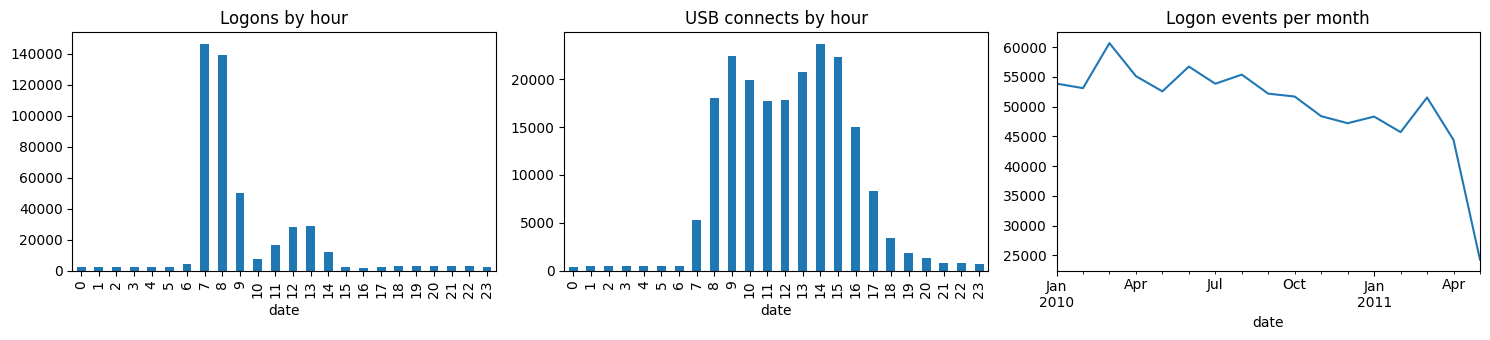

In [8]:
import matplotlib.pyplot as plt
R = f"{DATA_DIR}/r4.2"
FMT = "%m/%d/%Y %H:%M:%S"

logs = {
    "logon":  pd.read_csv(f"{R}/logon.csv",  usecols=["id", "date", "user", "pc", "activity"]),
    "device": pd.read_csv(f"{R}/device.csv", usecols=["id", "date", "user", "pc", "activity"]),
    "file":   pd.read_csv(f"{R}/file.csv",   usecols=["id", "date", "user", "pc"]),
}
for name, df in logs.items():
    df["date"] = pd.to_datetime(df["date"], format=FMT, errors="coerce")
    print(f"--- {name} ---")
    print("rows:", len(df), "| users:", df["user"].nunique(), "| pcs:", df["pc"].nunique())
    print("date range:", df["date"].min(), "to", df["date"].max())
    print("unparsed dates:", df["date"].isna().sum(), "| duplicate ids:", df["id"].duplicated().sum(),
          "| exact duplicate rows:", df.duplicated().sum())
    print("missing values:", df.isna().sum()[lambda s: s > 0].to_dict())
    if "activity" in df:
        print("activity:", df["activity"].value_counts().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
logs["logon"].query("activity == 'Logon'")["date"].dt.hour.value_counts().sort_index().plot.bar(ax=ax[0], title="Logons by hour")
logs["device"].query("activity == 'Connect'")["date"].dt.hour.value_counts().sort_index().plot.bar(ax=ax[1], title="USB connects by hour")
logs["logon"].groupby(logs["logon"]["date"].dt.to_period("M")).size().plot(ax=ax[2], title="Logon events per month")
plt.tight_layout(); plt.show()

In [9]:
import os, re, json, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = os.environ.get("CERT_DIR", "/content/drive/MyDrive/cert_r42")
R = f"{DATA_DIR}/r4.2"
OUT_DIR = f"{DATA_DIR}/outputs"            # figures and metrics for the report and slides (kept in Drive)
os.makedirs(OUT_DIR, exist_ok=True)
FMT = "%m/%d/%Y %H:%M:%S"

CUT = pd.Timestamp("2010-12-31")           # last training day (train = Jan-Dec 2010, test = 2011)
WORK_START, WORK_END = 8, 18               # after-hours = before 08:00 or from 18:00. Adjust after looking at the hour plots.
INTERNAL_DOMAIN = "@dtaa.com"              # employees use a DTAA address (dataset readme)
REVIEW_BUDGET = 0.01                       # analysts review the top 1% of test user-days
MINUTES_PER_REVIEW = 15                    # assumption for the business metric
print("DATA_DIR:", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_DIR: /content/drive/MyDrive/cert_r42


In [10]:
def read_log(name, cols):
    df = pd.read_csv(f"{R}/{name}.csv", usecols=cols)
    df["date"] = pd.to_datetime(df["date"], format=FMT, errors="coerce")
    bad = int(df["date"].isna().sum())
    if bad > 0.01 * len(df):
        raise ValueError(f"{name}: {bad} of {len(df)} dates did not match {FMT}. Paste this message to your helper.")
    return df.dropna(subset=["date"])

logon = read_log("logon", ["id", "date", "user", "pc", "activity"])
device = read_log("device", ["id", "date", "user", "pc", "activity"])
files = read_log("file", ["id", "date", "user", "pc"])

for name, df in [("logon", logon), ("device", device), ("file", files)]:
    print(f"--- {name} ---")
    print("rows:", len(df), "| users:", df["user"].nunique(), "| pcs:", df["pc"].nunique())
    print("date range:", df["date"].min(), "to", df["date"].max())
    print("duplicate ids:", int(df["id"].duplicated().sum()), "| exact duplicate rows:", int(df.duplicated().sum()),
          "| missing values:", int(df.isna().sum().sum()))
    if "activity" in df:
        print("activity:", df["activity"].value_counts().to_dict())

--- logon ---
rows: 854859 | users: 1000 | pcs: 1003
date range: 2010-01-02 06:49:00 to 2011-05-17 06:43:35
duplicate ids: 0 | exact duplicate rows: 0 | missing values: 0
activity: {'Logon': 470591, 'Logoff': 384268}
--- device ---
rows: 405380 | users: 265 | pcs: 971
date range: 2010-01-02 07:21:06 to 2011-05-16 23:22:34
duplicate ids: 0 | exact duplicate rows: 0 | missing values: 0
activity: {'Connect': 203339, 'Disconnect': 202041}
--- file ---
rows: 445581 | users: 264 | pcs: 956
date range: 2010-01-02 07:23:14 to 2011-05-16 23:22:34
duplicate ids: 0 | exact duplicate rows: 0 | missing values: 0


In [11]:
def hour_is_after(h):
    return ((h < WORK_START) | (h >= WORK_END)).astype(int)

def read_email():
    # First, let's peek at the file to see the actual column names
    header = pd.read_csv(f"{R}/email.csv", nrows=0).columns.tolist()
    print("Available email columns:", header)

    # Determine correct attachment count column (e.g., 'attachments' or 'attachment_count')
    att_col = "attachments" if "attachments" in header else ("attachment_count" if "attachment_count" in header else None)

    usecols = ["date", "user", "to", "cc", "bcc", "size"]
    if att_col:
        usecols.append(att_col)

    parts, n_rows, n_bad = [], 0, 0
    dom = re.escape(INTERNAL_DOMAIN)
    for ch in pd.read_csv(f"{R}/email.csv", usecols=usecols, chunksize=500_000):
        n_rows += len(ch)
        ch["date"] = pd.to_datetime(ch["date"], format=FMT, errors="coerce")
        n_bad += int(ch["date"].isna().sum())
        ch = ch.dropna(subset=["date"]).copy()
        total = np.zeros(len(ch), dtype=int)
        internal = np.zeros(len(ch), dtype=int)
        for c in ["to", "cc", "bcc"]:
            s = ch[c].fillna("").astype(str)
            total += np.where(s.eq(""), 0, s.str.count(";") + 1)
            internal += s.str.count(dom, flags=re.IGNORECASE).to_numpy()
        ch["rcpt"] = total
        ch["ext"] = np.maximum(total - internal, 0)
        ch["ext_mail"] = (ch["ext"] > 0).astype(int)

        if att_col:
            ch["has_att"] = (ch[att_col].fillna(0).astype(int) > 0).astype(int)
            ch["att_total"] = ch[att_col].fillna(0).astype(int)
        else:
            ch["has_att"] = 0
            ch["att_total"] = 0

        ch["ah"] = hour_is_after(ch["date"].dt.hour)
        ch["day"] = ch["date"].dt.normalize()
        parts.append(ch.groupby(["user", "day"]).agg(
            emails=("date", "size"), email_att=("has_att", "sum"), att_total=("att_total", "sum"),
            email_size=("size", "sum"), rcpts=("rcpt", "sum"), ext_rcpts=("ext", "sum"),
            ext_emails=("ext_mail", "sum"), ah_emails=("ah", "sum")).reset_index())
    return pd.concat(parts).groupby(["user", "day"], as_index=False).sum(), n_rows, n_bad

EMAIL_CACHE = f"{DATA_DIR}/email_user_day_{WORK_START}_{WORK_END}.pkl"
if os.path.exists(EMAIL_CACHE):
    email_d, email_rows, email_bad = pd.read_pickle(EMAIL_CACHE)
    print("loaded the cached email table")
else:
    email_d, email_rows, email_bad = read_email()
    pd.to_pickle((email_d, email_rows, email_bad), EMAIL_CACHE)
if email_bad > 0.01 * email_rows:
    raise ValueError(f"email: {email_bad} of {email_rows} dates did not match {FMT}. Paste this message to your helper.")

share_ext = email_d["ext_rcpts"].sum() / max(email_d["rcpts"].sum(), 1)
print("--- email ---")
print("rows:", email_rows, "| unparsed dates:", email_bad, "| user-days with email:", len(email_d),
      "| users:", email_d["user"].nunique())
print("date range:", email_d["day"].min(), "to", email_d["day"].max())
print("share of recipients outside", INTERNAL_DOMAIN, ":", round(float(share_ext), 3))
if share_ext > 0.95 or share_ext < 0.001:
    print("WARNING: the external share looks wrong, so the internal domain string is probably not right. Tell your helper.")

Available email columns: ['id', 'date', 'user', 'pc', 'to', 'cc', 'bcc', 'from', 'size', 'attachments', 'content']
--- email ---
rows: 2629979 | unparsed dates: 0 | user-days with email: 326985 | users: 1000
date range: 2010-01-02 00:00:00 to 2011-05-16 00:00:00
share of recipients outside @dtaa.com : 0.418


In [12]:
def with_day(df):
    df = df.copy()
    df["day"] = df["date"].dt.normalize()
    df["ah"] = hour_is_after(df["date"].dt.hour)
    df["wk"] = (df["date"].dt.dayofweek >= 5).astype(int)
    return df

lg = with_day(logon)
lg["is_logon"] = (lg["activity"].str.lower() == "logon").astype(int)
lg["ah_logon"] = lg["ah"] * lg["is_logon"]
lg["wk_logon"] = lg["wk"] * lg["is_logon"]
logon_d = lg.groupby(["user", "day"]).agg(
    logons=("is_logon", "sum"), ah_logons=("ah_logon", "sum"),
    wk_logons=("wk_logon", "sum"), pcs=("pc", "nunique")).reset_index()

dv = with_day(device)
dv["is_conn"] = (dv["activity"].str.lower() == "connect").astype(int)
dv["ah_conn"] = dv["ah"] * dv["is_conn"]
usb_d = dv.groupby(["user", "day"]).agg(usb_connects=("is_conn", "sum"), ah_usb=("ah_conn", "sum")).reset_index()

fl = with_day(files)
file_d = fl.groupby(["user", "day"]).agg(file_copies=("id", "size"), ah_file=("ah", "sum")).reset_index()

ud = logon_d
for t in (usb_d, file_d, email_d):
    ud = ud.merge(t, on=["user", "day"], how="outer")

COUNT_COLS = ["logons", "ah_logons", "wk_logons", "pcs", "usb_connects", "ah_usb", "file_copies", "ah_file",
              "emails", "email_att", "att_total", "email_size", "rcpts", "ext_rcpts", "ext_emails", "ah_emails"]
ud[COUNT_COLS] = ud[COUNT_COLS].fillna(0)
ud["email_size_log"] = np.log1p(ud["email_size"])
ud["is_weekend"] = (ud["day"].dt.dayofweek >= 5).astype(int)
FEATURES = ["logons", "ah_logons", "wk_logons", "pcs", "usb_connects", "ah_usb", "file_copies", "ah_file",
            "emails", "email_att", "att_total", "email_size_log", "rcpts", "ext_rcpts", "ext_emails", "ah_emails",
            "is_weekend"]
print("user-days before labels:", len(ud), "| users:", ud["user"].nunique(), "| days:", ud["day"].nunique())

user-days before labels: 330452 | users: 1000 | days: 501


In [13]:
RULES_PATH = f"{DATA_DIR}/label_rules.csv"

def build_label_rules():
    ins = pd.read_csv(f"{DATA_DIR}/answers/insiders.csv", dtype=str)
    insiders = set(ins.loc[ins["dataset"] == "4.2", "user"])
    rows = []
    for p in glob.glob(f"{DATA_DIR}/answers/r4.2-*/*.csv"):
        with open(p) as f:
            for line in f:
                parts = line.rstrip("\n").split(",")
                rows.append((parts[0], parts[1], parts[2], parts[3]))
    mal = pd.DataFrame(rows, columns=["type", "event_id", "date", "user"])
    mal["day"] = pd.to_datetime(mal["date"], format=FMT).dt.normalize()
    victims = set(mal["user"]) - insiders
    pos = (mal[(mal["type"] != "http") & mal["user"].isin(insiders)].drop_duplicates(["user", "day"])[["user", "day"]]
           .assign(action="positive", reason="malicious non-web event"))
    web = (mal[(mal["type"] == "http") & mal["user"].isin(insiders)].drop_duplicates(["user", "day"])[["user", "day"]]
           .merge(pos[["user", "day"]], how="left", on=["user", "day"], indicator=True))
    web = web[web["_merge"] == "left_only"][["user", "day"]].assign(action="exclude", reason="web-only malicious day")
    vic = (mal[mal["user"].isin(victims)].drop_duplicates(["user", "day"])[["user", "day"]]
           .assign(action="exclude", reason="victim account used by an insider"))
    return pd.concat([pos, web, vic], ignore_index=True)

if os.path.exists(RULES_PATH):
    rules = pd.read_csv(RULES_PATH, parse_dates=["day"])
else:
    rules = build_label_rules()
    rules.to_csv(RULES_PATH, index=False)
print(rules.groupby(["action", "reason"]).size().to_string())
print("on the real data you should see: positive 521 | exclude 445 (web-only) | exclude 20 (victim)")

rules = rules[["user", "day", "action"]].drop_duplicates()
assert not rules.duplicated(["user", "day"]).any(), "a user-day has two conflicting label rules"

ud = ud.merge(rules, on=["user", "day"], how="left")
n_pos_rules = int((rules["action"] == "positive").sum())
n_pos_found = int((ud["action"] == "positive").sum())
print("positive labels matched in the logs:", n_pos_found, "of", n_pos_rules)
if n_pos_found != n_pos_rules:
    print("WARNING: some positive days are not in the logs. Tell your helper.")
print("excluded user-days (web-only malicious days, victim accounts):", int((ud["action"] == "exclude").sum()))

ud = ud[ud["action"] != "exclude"].copy()
ud["y"] = (ud["action"] == "positive").astype(int)
ud = ud.drop(columns=["action"])
print("user-days used:", len(ud), "| positives:", int(ud["y"].sum()), "| rate:", round(float(ud["y"].mean()) * 100, 3), "%")

try:
    ud.to_parquet(f"{DATA_DIR}/user_day.parquet", index=False)
except Exception:
    ud.to_pickle(f"{DATA_DIR}/user_day.pkl")
print("saved the user-day table to Drive (never commit it to GitHub)")

action    reason                           
exclude   victim account used by an insider     20
          web-only malicious day               445
positive  malicious non-web event              521
on the real data you should see: positive 521 | exclude 445 (web-only) | exclude 20 (victim)
positive labels matched in the logs: 521 of 521
excluded user-days (web-only malicious days, victim accounts): 465
user-days used: 329987 | positives: 521 | rate: 0.158 %
saved the user-day table to Drive (never commit it to GitHub)


train: 246074 user-days | 391 positives | 56 insiders
test:  83913 user-days | 130 positives | 18 insiders
test users with no training history: 0


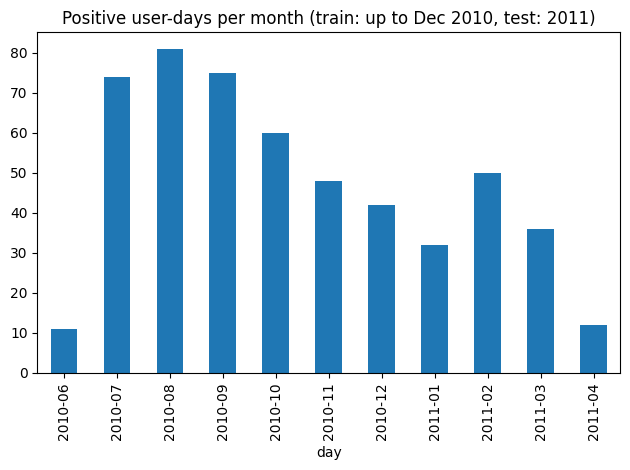

In [14]:
train = ud[ud["day"] <= CUT].reset_index(drop=True)
test = ud[ud["day"] > CUT].reset_index(drop=True)
X_train, y_train = train[["user", "day"] + FEATURES], train["y"]
X_test, y_test = test[["user", "day"] + FEATURES], test["y"]
print("train:", len(train), "user-days |", int(y_train.sum()), "positives |",
      train.loc[train["y"] == 1, "user"].nunique(), "insiders")
print("test: ", len(test), "user-days |", int(y_test.sum()), "positives |",
      test.loc[test["y"] == 1, "user"].nunique(), "insiders")
print("test users with no training history:", len(set(test["user"]) - set(train["user"])))
assert y_train.sum() > 0 and y_test.sum() > 0, "both splits need positive days: move CUT"

pos_by_month = ud[ud["y"] == 1].groupby(ud["day"].dt.to_period("M")).size()
pos_by_month.plot.bar(title="Positive user-days per month (train: up to Dec 2010, test: 2011)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/positives_by_month.png", dpi=150)
plt.show()

In [15]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

DEV_COLS = ["logons", "ah_logons", "usb_connects", "ah_usb", "file_copies", "emails", "email_att", "ext_emails", "ext_rcpts"]

class UserBaseline(BaseEstimator, TransformerMixin):
    """Adds how far each day is from that user's own normal. Statistics come from the rows passed to fit only."""
    def __init__(self, cols=None, min_days=5):
        self.cols = cols
        self.min_days = min_days

    def fit(self, X, y=None):
        base = X if y is None else X[np.asarray(y) == 0]
        g = base.groupby("user")[self.cols]
        self.mean_ = g.mean()
        self.std_ = g.std().fillna(0)
        self.count_ = g.size()
        self.global_mean_ = base[self.cols].mean()
        self.global_std_ = base[self.cols].std().fillna(1).replace(0, 1)
        self.n_rows_fit_ = len(base)
        self.fit_last_day_ = base["day"].max()
        return self

    def transform(self, X):
        base = X[self.cols]
        mu = self.mean_.reindex(X["user"]).to_numpy()
        sd = self.std_.reindex(X["user"]).to_numpy()
        n = self.count_.reindex(X["user"]).fillna(0).to_numpy()
        unseen = (n < self.min_days) | np.isnan(mu).any(axis=1)
        mu = np.where(unseen[:, None], self.global_mean_.to_numpy(), mu)
        sd = np.where(unseen[:, None], self.global_std_.to_numpy(), sd)
        sd = np.where(sd < 1e-6, 1.0, sd)
        dev = np.clip((base.to_numpy() - mu) / sd, -10, 10)
        dev = pd.DataFrame(dev, index=X.index, columns=[f"{c}_dev" for c in self.cols])
        rest = X[[c for c in X.columns if c not in ("user", "day")]]
        return pd.concat([rest, dev], axis=1)

def make_pipeline(C=1.0):
    return Pipeline([
        ("user_baseline", UserBaseline(cols=DEV_COLS)),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEED)),
    ])


In [16]:
from sklearn.metrics import average_precision_score

VAL_START = pd.Timestamp("2010-10-01")     # fit on Jan-Sep 2010, validate on Oct-Dec 2010
fit_mask = X_train["day"] < VAL_START
Xf, yf = X_train[fit_mask], y_train[fit_mask]
Xv, yv = X_train[~fit_mask], y_train[~fit_mask]
print("fit part:", len(Xf), "user-days,", int(yf.sum()), "positives | validation part:", len(Xv), "user-days,",
      int(yv.sum()), "positives,", Xv.loc[yv == 1, "user"].nunique(), "insiders")
assert yf.sum() > 0 and yv.sum() > 0, "both parts need positive days: move VAL_START"

def recall_at_budget(y_true, s, budget=REVIEW_BUDGET):
    y_true = np.asarray(y_true)
    top_ = np.argsort(-s, kind="stable")[:int(np.ceil(budget * len(s)))]
    return float(y_true[top_].sum() / max(y_true.sum(), 1))

rows = []
for C in [0.01, 0.1, 1.0, 10.0]:
    m = make_pipeline(C).fit(Xf, yf)
    s = m.predict_proba(Xv)[:, 1]
    rows.append({"C": C, "val PR-AUC": round(float(average_precision_score(yv, s)), 4),
                 "val recall@budget": round(recall_at_budget(yv, s), 3)})
val_table = pd.DataFrame(rows)
print(val_table.to_string(index=False))
BEST_C = float(val_table.sort_values(["val PR-AUC", "C"], ascending=[False, True]).iloc[0]["C"])
print("chosen C:", BEST_C, "| validation prevalence:", round(float(yv.mean()), 4))

baseline = make_pipeline(BEST_C).fit(X_train, y_train)
print("final pipeline refitted on all", len(X_train), "training rows. The test set has not been touched yet.")

fit part: 189007 user-days, 241 positives | validation part: 57067 user-days, 150 positives, 26 insiders
    C  val PR-AUC  val recall@budget
 0.01      0.1309              0.467
 0.10      0.1198              0.473
 1.00      0.1183              0.467
10.00      0.1180              0.467
chosen C: 0.01 | validation prevalence: 0.0026
final pipeline refitted on all 246074 training rows. The test set has not been touched yet.


In [17]:
from sklearn.metrics import average_precision_score

scores = baseline.predict_proba(X_test)[:, 1]
prevalence = float(y_test.mean())
ap_real = float(average_precision_score(y_test, scores))

ub = baseline.named_steps["user_baseline"]
fed_to_model = list(baseline.named_steps["scale"].feature_names_in_)
structural = {
    "train ends before test starts": bool(X_train["day"].max() < X_test["day"].min()),
    "validation period is inside training and comes before test": bool(Xf["day"].max() < Xv["day"].min() <= Xv["day"].max() < X_test["day"].min()),
    "no (user, day) row in both sets": X_train[["user", "day"]].merge(X_test[["user", "day"]]).shape[0] == 0,
    "label and rule columns are not features": not ({"y", "action", "reason"} & set(FEATURES)),
    "user id and date never reach the classifier": not ({"user", "day"} & set(fed_to_model)),
    "per-user baseline learned from days up to the cut only": bool(ub.fit_last_day_ <= CUT),
    "baseline excludes malicious training days": int(ub.n_rows_fit_) == int((y_train == 0).sum()),
    "scaler fitted on training rows only": int(baseline.named_steps["scale"].n_samples_seen_) == len(X_train),
}
for k_, v_ in structural.items():
    print("[x]" if v_ else "[ ]", k_)
assert all(structural.values()), "a leakage check failed, fix it before trusting any score"

# Label-shuffle (permutation) test. A model trained on shuffled labels learns random coefficients. Insider days are extreme
# outliers, so a lucky sign can still rank them high: single shuffles can land well above chance. What must hold is that the
# real model beats every shuffled-label model, so its score cannot be reproduced from noise.
rng = np.random.default_rng(SEED)
ap_shuf = []
for _ in range(8):
    y_shuf = pd.Series(rng.permutation(y_train.to_numpy()), index=y_train.index)
    shuffled = clone(baseline).fit(X_train, y_shuf)
    ap_shuf.append(float(average_precision_score(y_test, shuffled.predict_proba(X_test)[:, 1])))
beats_all = ap_real > max(ap_shuf)
print("[x]" if beats_all else "[ ]", "real PR-AUC beats all 8 label-shuffled models")
print(f"real PR-AUC {ap_real:.3f} | shuffled-label PR-AUC: min {min(ap_shuf):.3f}, median {np.median(ap_shuf):.3f}, "
      f"max {max(ap_shuf):.3f} | chance level (prevalence) {prevalence:.4f}")
if not beats_all:
    print("Not necessarily a leak: with few test insiders the score is noisy. Paste this output to your helper.")

[x] train ends before test starts
[x] validation period is inside training and comes before test
[x] no (user, day) row in both sets
[x] label and rule columns are not features
[x] user id and date never reach the classifier
[x] per-user baseline learned from days up to the cut only
[x] baseline excludes malicious training days
[x] scaler fitted on training rows only
[x] real PR-AUC beats all 8 label-shuffled models
real PR-AUC 0.049 | shuffled-label PR-AUC: min 0.001, median 0.002, max 0.027 | chance level (prevalence) 0.0015


     operating point  flagged    TN   FP  FN  TP  precision  recall    F1
       threshold 0.5     4151 79737 4046  25 105      0.025   0.808 0.049
top 1% review budget      840 82990  793  83  47      0.056   0.362 0.097

PR-AUC 0.0493 (random ranking would give about 0.0015) | accuracy of 'nobody is an insider': 0.9985

Review budget: top 1% of test user-days = 840 reviews
insider days found: 47 of 130 -> recall@budget 0.362 | precision@budget 0.056
random ranking would find about 1.3 insider days (recall about 0.010)
insiders caught at least once: 13 of 18

Business metric (assumption: 15 min per review)
review everything: 20,978 analyst hours | review the watch-list: 210 hours | saved: 20,768 hours while finding 47 of 130 insider days
analyst hours per insider day found: 4.5 (reviewing everything: 161.4)

Largest coefficients (positive = raises the risk score):
usb_connects      1.10
email_size_log   -1.01
emails            0.98
file_copies      -0.98
wk_logons        -0.79
emails_

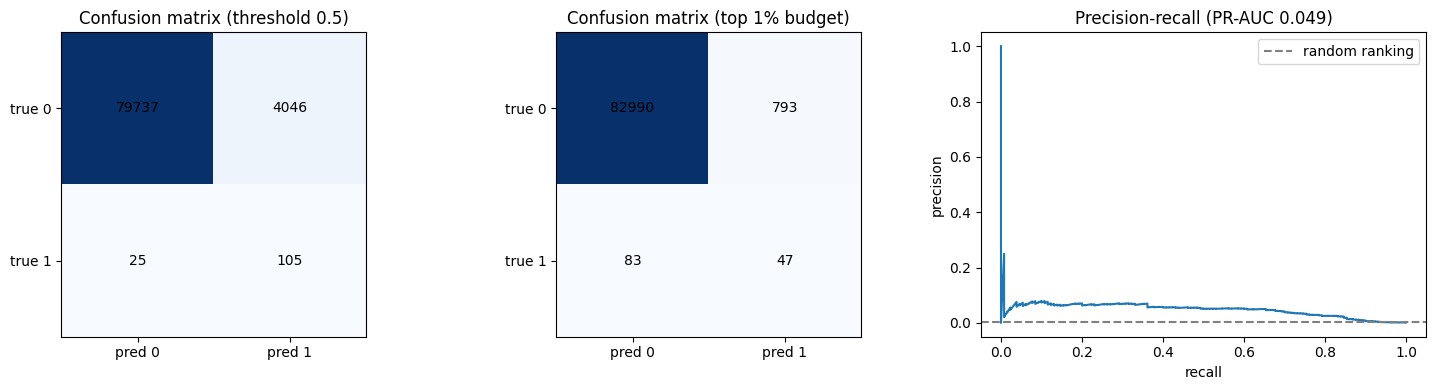


saved figures and phase1_metrics.json to /content/drive/MyDrive/cert_r42/outputs


In [18]:
from sklearn.metrics import confusion_matrix, precision_recall_curve

y_arr = y_test.to_numpy()
k = int(np.ceil(REVIEW_BUDGET * len(y_arr)))
top = np.argsort(-scores, kind="stable")[:k]
flag_budget = np.zeros(len(y_arr), dtype=bool)
flag_budget[top] = True

def op_point(name, pred):
    tn, fp, fn, tp = confusion_matrix(y_arr, np.asarray(pred).astype(int), labels=[0, 1]).ravel()
    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) else 0.0
    return {"operating point": name, "flagged": int(tp + fp), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "precision": round(p, 3), "recall": round(r, 3), "F1": round(f1, 3)}

table = pd.DataFrame([op_point("threshold 0.5", scores >= 0.5),
                      op_point(f"top {REVIEW_BUDGET:.0%} review budget", flag_budget)])
print(table.to_string(index=False))

ap = float(average_precision_score(y_arr, scores))
print(f"\nPR-AUC {ap:.4f} (random ranking would give about {prevalence:.4f}) | "
      f"accuracy of 'nobody is an insider': {1 - prevalence:.4f}")

hits = int(y_arr[top].sum())
test_insiders = set(test.loc[test["y"] == 1, "user"])
caught = set(test.iloc[top].loc[test.iloc[top]["y"] == 1, "user"])
print(f"\nReview budget: top {REVIEW_BUDGET:.0%} of test user-days = {k} reviews")
print(f"insider days found: {hits} of {int(y_arr.sum())} -> recall@budget {hits / y_arr.sum():.3f} | precision@budget {hits / k:.3f}")
print(f"random ranking would find about {k * prevalence:.1f} insider days (recall about {REVIEW_BUDGET:.3f})")
print(f"insiders caught at least once: {len(caught)} of {len(test_insiders)}")

hours_all = len(y_arr) * MINUTES_PER_REVIEW / 60
hours_budget = k * MINUTES_PER_REVIEW / 60
print(f"\nBusiness metric (assumption: {MINUTES_PER_REVIEW} min per review)")
print(f"review everything: {hours_all:,.0f} analyst hours | review the watch-list: {hours_budget:,.0f} hours "
      f"| saved: {hours_all - hours_budget:,.0f} hours while finding {hits} of {int(y_arr.sum())} insider days")
if hits:
    print(f"analyst hours per insider day found: {hours_budget / hits:.1f} (reviewing everything: {hours_all / y_arr.sum():.1f})")

coef = pd.Series(baseline.named_steps["clf"].coef_[0], index=baseline.named_steps["scale"].feature_names_in_)
print("\nLargest coefficients (positive = raises the risk score):")
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(8).round(2).to_string())

cm_b = confusion_matrix(y_arr, flag_budget.astype(int), labels=[0, 1])
cm_5 = confusion_matrix(y_arr, (scores >= 0.5).astype(int), labels=[0, 1])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, cm, title in [(ax[0], cm_5, "Confusion matrix (threshold 0.5)"), (ax[1], cm_b, f"Confusion matrix (top {REVIEW_BUDGET:.0%} budget)")]:
    a.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        a.text(j, i, int(v), ha="center", va="center")
    a.set_xticks([0, 1], ["pred 0", "pred 1"])
    a.set_yticks([0, 1], ["true 0", "true 1"])
    a.set_title(title)
p_, r_, _ = precision_recall_curve(y_arr, scores)
ax[2].plot(r_, p_)
ax[2].axhline(prevalence, ls="--", c="grey", label="random ranking")
ax[2].set_xlabel("recall")
ax[2].set_ylabel("precision")
ax[2].set_title(f"Precision-recall (PR-AUC {ap:.3f})")
ax[2].legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/baseline_results.png", dpi=150)
plt.show()

summary = {
    "train_user_days": len(train), "train_positives": int(y_train.sum()),
    "test_user_days": len(test), "test_positives": int(y_arr.sum()), "test_insiders": len(test_insiders),
    "prevalence": prevalence, "pr_auc": ap, "shuffled_pr_auc_max": max(ap_shuf), "shuffled_pr_auc_median": float(np.median(ap_shuf)),
    "threshold_0.5": table.iloc[0].to_dict(), "review_budget": table.iloc[1].to_dict(),
    "chosen_C": BEST_C, "validation": val_table.to_dict("records"), "insiders_caught": len(caught), "hours_review_everything": hours_all, "hours_watchlist": hours_budget,
    "minutes_per_review": MINUTES_PER_REVIEW, "work_hours": [WORK_START, WORK_END], "cut": str(CUT.date()),
}
with open(f"{OUT_DIR}/phase1_metrics.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
print("\nsaved figures and phase1_metrics.json to", OUT_DIR)

In [19]:
chk = train[FEATURES]
print("missing values:", int(chk.isna().sum().sum()), "| negative values:", int((chk < 0).sum().sum()))
print("constant columns:", [c for c in FEATURES if train[c].nunique() <= 1])
print(train[FEATURES].describe(percentiles=[.5, .99, .999]).T[["50%", "99%", "99.9%", "max"]].round(1).to_string())

corr = train[FEATURES].corr().abs()
pairs = [(a, b, round(float(corr.loc[a, b]), 3)) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:] if corr.loc[a, b] > 0.95]
print("\npairs with |correlation| > 0.95:", pairs)

em_ids = pd.read_csv(f"{R}/email.csv", usecols=["id", "size"])
print("email: duplicate ids:", int(em_ids["id"].duplicated().sum()), "| missing size:", int(em_ids["size"].isna().sum()))
del em_ids

missing values: 0 | negative values: 0
constant columns: []
                 50%   99%  99.9%    max
logons           1.0   5.0    7.0    9.0
ah_logons        0.0   4.0    6.0    8.0
wk_logons        0.0   2.0    3.0    7.0
pcs              1.0   5.0    6.0    7.0
usb_connects     0.0   9.0   13.0   14.0
ah_usb           0.0   2.0    5.0   12.0
file_copies      0.0  27.0   30.0   54.0
ah_file          0.0   4.0   17.0   43.0
emails           9.0  18.0   27.0   36.0
email_att        1.0   8.0   12.0   18.0
att_total        1.0  18.0   27.0   50.0
email_size_log  12.5  13.3   13.7   14.0
rcpts           18.0  61.0   84.0  102.0
ext_rcpts        5.0  37.0   60.0   80.0
ext_emails       3.0  14.0   22.0   33.0
ah_emails        0.0   9.0   14.0   27.0
is_weekend       0.0   1.0    1.0    1.0

pairs with |correlation| > 0.95: []
email: duplicate ids: 0 | missing size: 0


In [20]:
COUNTS = [c for c in FEATURES if c not in ("email_size_log", "is_weekend")]

def prep(X, log):
    X = X.copy()
    if log:
        X[COUNTS] = np.log1p(X[COUNTS])
    return X

def run_variant(name, log=False, drop_corr=False):
    Xf_, Xv_ = prep(Xf, log), prep(Xv, log)
    drop = []
    if drop_corr:
        cm = Xf_.drop(columns=["user", "day"]).corr().abs()
        cols = list(cm.columns)
        drop = sorted({b for i, a in enumerate(cols) for b in cols[i + 1:] if cm.loc[a, b] > 0.95})
        Xf_, Xv_ = Xf_.drop(columns=drop), Xv_.drop(columns=drop)
    dev = [c for c in DEV_COLS if c in Xf_.columns]
    best = None
    for C in [0.01, 0.1, 1.0, 10.0]:
        pipe = Pipeline([("user_baseline", UserBaseline(cols=dev)), ("scale", StandardScaler()),
                         ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEED))])
        pipe.fit(Xf_, yf)
        s = pipe.predict_proba(Xv_)[:, 1]
        row = {"variant": name, "features": Xf_.shape[1] - 2, "best C": C,
               "val PR-AUC": round(float(average_precision_score(yv, s)), 4),
               "val recall@budget": round(recall_at_budget(yv, s), 3), "dropped": drop}
        if best is None or row["val PR-AUC"] > best["val PR-AUC"]:
            best = row
    return best

results = pd.DataFrame([
    run_variant("A: current (raw counts)"),
    run_variant("B: log1p on counts", log=True),
    run_variant("C: log1p + drop overlapping features", log=True, drop_corr=True),
])
print(results.drop(columns="dropped").to_string(index=False))
print("features dropped in C:", results.loc[2, "dropped"])

                             variant  features  best C  val PR-AUC  val recall@budget
             A: current (raw counts)        17    0.01      0.1309              0.467
                  B: log1p on counts        17    0.01      0.0714              0.240
C: log1p + drop overlapping features        14    0.01      0.0593              0.213
features dropped in C: ['att_total', 'ext_emails', 'is_weekend']


In [21]:
import os

drive = "/content/drive/MyDrive"

target_files = {
    "logon.csv",
    "device.csv",
    "file.csv",
    "email.csv",
    "http.csv"
}

for root, dirs, files in os.walk(drive):
    for filename in files:
        if filename.lower() in target_files:
            print(os.path.join(root, filename))

/content/drive/MyDrive/cert_r42/r4.2/device.csv
/content/drive/MyDrive/cert_r42/r4.2/logon.csv
/content/drive/MyDrive/cert_r42/r4.2/file.csv
/content/drive/MyDrive/cert_r42/r4.2/email.csv


In [22]:
import os

for folder in [
    "/content/drive",
    "/content",
    "/content/drive/MyDrive/cert_r42",
]:
    print(f"\n--- {folder} ---")
    if os.path.exists(folder):
        print(os.listdir(folder))
    else:
        print("Folder does not exist")


--- /content/drive ---
['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']

--- /content ---
['.config', 'drive', 'sample_data']

--- /content/drive/MyDrive/cert_r42 ---
['r4.2', 'answers', 'outputs', 'label_rules.csv', 'email_user_day_8_18.pkl', 'user_day.parquet']


In [23]:
import os

base = "/content/drive/MyDrive/cert_r42"

for name in [
    "user_day.parquet",
    "user_day.pkl",
    "email_user_day_8_18.pkl",
    "label_rules.csv"
]:
    path = os.path.join(base, name)
    print(name, "FOUND" if os.path.exists(path) else "MISSING")

user_day.parquet FOUND
user_day.pkl MISSING
email_user_day_8_18.pkl FOUND
label_rules.csv FOUND


In [ ]:
import os

for base in [
    "/content/drive/.shortcut-targets-by-id",
    "/content/drive/.Trash-0"
]:
    print("\nSearching:", base)

    if not os.path.exists(base):
        print("Not accessible")
        continue

    for root, dirs, files in os.walk(base):
        for f in files:
            if f.lower() in {
                "logon.csv", "device.csv", "file.csv",
                "email.csv", "http.csv"
            }:
                print("FOUND:", os.path.join(root, f))


Searching: /content/drive/.shortcut-targets-by-id

Searching: /content/drive/.Trash-0


In [24]:
import os
import pandas as pd

R = "/content/drive/MyDrive/cert_r42/r4.2"

required = ["logon.csv", "device.csv", "file.csv", "email.csv"]

for name in required:
    path = os.path.join(R, name)
    assert os.path.isfile(path), f"Missing: {name}"
    print(f"OK: {name} | {os.path.getsize(path) / (1024**3):.2f} GB")

print("\nAll four required activity logs are available.")

OK: logon.csv | 0.05 GB
OK: device.csv | 0.03 GB
OK: file.csv | 0.18 GB
OK: email.csv | 1.27 GB

All four required activity logs are available.
